# 02 - Critical positions (Stockfish)

**Pytanie:** w ilu pozycjach istnieje tylko jeden dobry ruch (reszta wyraźnie gorsza), i jak często gracze o różnym Elo znajdują ten ruch - w podziale na figurę, którą trzeba było ruszyć.

**Definicja pozycji krytycznej:** Stockfish liczy dwa najlepsze ruchy (MultiPV=2). Porównujemy ich *szanse na wygraną* (nie surowe centipiony). Jeśli `win_prob(najlepszy) - win_prob(drugi) >= 0.20`, pozycja jest krytyczna. Wtedy każdy ruch inny niż najlepszy jest co najmniej o tyle gorszy, więc `found_best == False` oznacza realny błąd.

**Wymaga:** pliku Stockfisha (.exe) - pobierz ze https://stockfishchess.org/download/ (Windows), rozpakuj i skopiuj plik .exe do folderu `engine/` w projekcie jako `stockfish.exe`.

In [1]:
# Windows + Jupyter: bez tego python-chess nie umie uruchomić silnika (NotImplementedError)
import asyncio, sys
if sys.platform == 'win32':
    asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())

sys.path.append('../src')

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from critical import find_critical_positions

# >>> plik Stockfisha (.exe) wrzuć do folderu engine/ w projekcie <<<
ENGINE_PATH =r"C:\Users\him3c\Documents\Praca magisterska\chess-features-thesis\stockfish\stockfish-windows-x86-64-universal.exe"   # wrzuć tu plik Stockfisha i nazwij go stockfish.exe
PGN_PATH = '../data/lichess_db_standard_rated_2026-08.pgn.zst' # albo ../data/sample.pgn

## 1. Sprawdź, czy silnik działa
Powinno wypisać dwa najlepsze ruchy z pozycji początkowej. Jeśli jest błąd ścieżki, popraw `ENGINE_PATH`.

In [2]:
import chess, chess.engine

with chess.engine.SimpleEngine.popen_uci(ENGINE_PATH) as eng:
    infos = eng.analyse(chess.Board(), chess.engine.Limit(depth=10), multipv=2)
    for i in infos:
        print(i['pv'][0], i['score'])

e2e4 PovScore(Cp(+24), WHITE)
d2d4 PovScore(Cp(+13), WHITE)


## 1b. Rejestr przeanalizowanych partii
Żeby nie analizować drugi raz tych samych partii, każda analiza zapisuje partię do rejestru `../data/analysed_games.csv` (klucz = adres partii na Lichess) razem z liczbą znalezionych pozycji krytycznych:

- `complete = True` - przeanalizowano **wszystkie** pozycje partii, więc `n_critical` jest dokładne (0, 1, 2, ...),
- `complete = False` - analiza częściowa (np. przerwana po znalezieniu 2 pozycji krytycznych), więc `n_critical` to tylko „co najmniej tyle”; prawdziwa liczba: **nie wiadomo**.

Kolejne analizy (sekcje 2, 2b, 2c) dostały parametr `registry_path` i pomijają partie z rejestru.

In [4]:
from registry import backfill_registry, load_registry, critical_distribution, export_registry_xlsx

REGISTRY_CSV  = '../data/analysed_games.csv'
REGISTRY_XLSX = '../data/analysed_games.xlsx'


In [5]:
# Podgląd rejestru + zapis do Excela (arkusze: partie / rozklad_krytycznych / opis)
reg = load_registry(REGISTRY_CSV)
print(f"{len(reg)} partii w rejestrze, w tym przeanalizowanych w całości: {int(reg['complete'].sum())}")
display(critical_distribution(reg))

# zamknij plik w Excelu przed zapisem, inaczej Windows go zablokuje
export_registry_xlsx(REGISTRY_CSV, REGISTRY_XLSX)

11641 partii w rejestrze, w tym przeanalizowanych w całości: 3514


,liczba_pozycji_krytycznych,partie,udzial
0,0 (pewne),541,0.0465
1,1 (pewne),530,0.0455
2,2 (pewne),493,0.0424
3,3 (pewne),447,0.0384
4,4 (pewne),363,0.0312
5,5+ (pewne),1140,0.0979
6,"nie wiadomo - analiza niepelna, znaleziono 0",6397,0.5495
7,"nie wiadomo - analiza niepelna, znaleziono 1 l...",1730,0.1486


zapisano: ../data/analysed_games.xlsx


## 2. Analiza partii (WOLNA, wznawialna)
Wyniki są dopisywane do `../data/critical_positions.csv` co kilka partii. **Możesz w każdej chwili przerwać komórkę (Stop) i uruchomić ją ponownie - program pominie już policzone partie i kontynuuje.**

- `max_games=None` = cały plik. Uwaga: miesięczny zrzut Lichess to dziesiątki milionów partii - całości nie da się przeanalizować (jedna partia ≈ kilka sekund). Realnie: kilka tysięcy partii.
- `quota_edges` + `games_per_bin` = zbieraj po tyle samo partii w każdym przedziale Elo (średnie Elo obu graczy), żeby mieć sensowną próbkę także dla bardzo słabych i bardzo mocnych graczy. Zatrzymuje się, gdy wszystkie przedziały są pełne.
- Przedziały Elo do ANALIZY (sekcja 3) są niezależne - zmienisz je bez ponownego liczenia.

In [6]:
CSV_PATH = '../data/critical_positionsv2.csv'

df = find_critical_positions(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=CSV_PATH,
    max_games=None,                        # None = do końca pliku / do zapełnienia kwot
    quota_edges=[0, 1200, 1600,2400 ,4000],  # przedziały do próbkowania
    games_per_bin=500,                     # tyle partii na przedział
    sample_prob=0.01,
    depth=12,
    gap_threshold=0.20,
    min_ply=8,
    threads=4,                             # ustaw ~liczbę rdzeni CPU
    save_every=10,
    registry_path=REGISTRY_CSV,   # pomija partie z rejestru i dopisuje nowe
)
print(df.shape)

games analysed: 2135it [00:00, ?it/s]


(132460, 18)


## 2b. Szukaj pozycji krytycznych, aż będzie ich tyle, ile trzeba
Losowa kolejność pozycji w partii; partia bez pozycji krytycznych jest po prostu pomijana i program idzie do następnej - szuka, **aż w każdym przedziale Elo będzie `target_per_bin` pozycji krytycznych**. Przedziały dotyczą Elo gracza, który miał ruch. Zapisuje tylko pozycje krytyczne do `critical_random.csv` (wznawialnie: możesz przerwać i uruchomić ponownie).

Z tego zbioru policzysz: *wśród pozycji krytycznych, jak często znaleziono najlepszy ruch - wg Elo i figury*. Nie policzysz z niego udziału pozycji krytycznych we wszystkich (do tego służy sekcja 2).

In [7]:
from critical import collect_critical_positions

CSV_RANDOM = '../data/critical_randomv2.csv'

dfc = collect_critical_positions(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=CSV_RANDOM,
    target_per_bin=100,                        # tyle pozycji krytycznych w KAŻDYM przedziale Elo
    elo_edges=[0, 1200, 1600,2400 ,4000],     # None = jeden wspólny cel
    depth=12,
    gap_threshold=0.20,
    max_critical_per_game=2,                   # max pozycji z jednej partii
    max_positions_per_game=40,                 # ile losowych pozycji sprawdzić w partii
    sample_prob=1.0,                           # <1.0 = losowy ułamek partii z całego pliku
    threads=4,
    registry_path=REGISTRY_CSV,   # pomija partie z rejestru i dopisuje nowe
)
dfc.shape

critical positions found: 100%|██████████| 400/400 [00:00<?, ?it/s]

found per bin: {0: 100, 1: 100, 2: 100, 3: 100} | games scanned this run: 0


(400, 18)

In [8]:
bins = [0, 1200, 1600,2400 ,4000]   # tu możesz zmieniać przedziały do analizy
labels = ['<1200', '1200-1600', '1600-2400', '2400+']
dfc = pd.read_csv(CSV_RANDOM)
dfc['elo_bin'] = pd.cut(dfc['player_elo'], bins=bins, labels=labels)

pd.DataFrame({
    'critical_positions': dfc.groupby('elo_bin', observed=True).size(),
    'found_best_rate': dfc.groupby('elo_bin', observed=True)['found_best'].mean(),
})

,critical_positions,found_best_rate
elo_bin,,
<1200,100,0.66
1200-1600,100,0.84
1600-2400,100,0.83
2400+,100,0.85


## 2c. Po tyle samo pozycji krytycznych dla każdej figury
Zbiera pozycje krytyczne tak, żeby **najlepszy ruch każdej figury** (pion, skoczek, goniec, wieża, hetman, król) miał tyle samo przypadków (`target_per_piece`). Wyniki do `critical_by_piece.csv` (wznawialnie).

- `elo_edges=None` - po `target_per_piece` na figurę, bez podziału na Elo.
- `elo_edges=[...]` - po `target_per_piece` pozycji w **każdej parze figura × przedział Elo** (6 × 4 × cel). Dzięki temu równo jest i figur, i Elo jednocześnie - ale to dużo pozycji, więc zacznij od małego celu (np. 10-30).
- Hetman, goniec i król rzadko bywają jedynym dobrym ruchem, więc ich zapełnienie może trwać długo - możesz przerwać komórkę w każdej chwili.
- Porównuj odsetek znalezionych ruchów **figura po figurze**; ogólna średnia z takiej próbki nie jest reprezentatywna.

In [9]:
from critical import collect_critical_by_piece

CSV_PIECE = '../data/critical_by_piecev2.csv'

dfp = collect_critical_by_piece(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=CSV_PIECE,
    target_per_piece=30,        # tyle pozycji w KAŻDEJ parze (figura x przedział Elo); 6 figur x 4 przedziały x 30 = 720
    elo_edges=[0, 1200, 1600, 2400, 4000],   # równo po figurach I po Elo; None = tylko po figurach
    depth=12,
    gap_threshold=0.20,
    max_critical_per_game=2,
    max_positions_per_game=40,
    sample_prob=1.0,
    threads=4,
    registry_path=REGISTRY_CSV,   # pomija partie z rejestru i dopisuje nowe
)
dfp.shape

critical positions found: 100%|██████████| 720/720 [00:00<?, ?it/s]

found per piece (rows) / Elo bin (columns):
         0   1   2   3
bishop  30  30  30  30
king    30  30  30  30
knight  30  30  30  30
pawn    30  30  30  30
queen   30  30  30  30
rook    30  30  30  30
games scanned this run: 0


(720, 18)

In [10]:
dfp = pd.read_csv(CSV_PIECE)
dfp['elo_bin'] = pd.cut(dfp['player_elo'], bins=[0, 1200, 1600, 2400, 4000],
                        labels=['<1200', '1200-1600', '1600-2000', '2000+'])

# kontrola: ile pozycji w każdej parze figura x Elo (powinno być równo)
display(pd.crosstab(dfp['best_piece'], dfp['elo_bin']))

# odsetek znalezionych najlepszych ruchów - wg figury
by_piece = dfp.groupby('best_piece').agg(n=('found_best', 'size'), found_best_rate=('found_best', 'mean'))
display(by_piece)

# ... i wg figury x Elo (uważaj na małe n w komórkach)
pd.crosstab(dfp['best_piece'], dfp['elo_bin'], values=dfp['found_best'], aggfunc='mean').round(2)

elo_bin,<1200,1200-1600,1600-2000,2000+
best_piece,,,,
bishop,30,30,30,30
king,30,30,30,30
knight,30,30,30,30
pawn,30,30,30,30
queen,30,30,30,30
rook,30,30,30,30


,n,found_best_rate
best_piece,,
bishop,120,0.791667
king,120,0.800000
knight,120,0.725000
pawn,120,0.833333
queen,120,0.733333
rook,120,0.775000


elo_bin,<1200,1200-1600,1600-2000,2000+
best_piece,,,,
bishop,0.83,0.70,0.77,0.87
king,0.70,0.77,0.90,0.83
knight,0.67,0.70,0.83,0.70
pawn,0.77,0.80,0.97,0.80
queen,0.47,0.77,0.90,0.80
rook,0.77,0.73,0.83,0.77


## 3. Podstawowe statystyki

In [11]:
# Wczytaj zapisane wyniki - NIE trzeba ponownie uruchamiać Stockfisha
df = pd.read_csv('../data/critical_positionsv2.csv')

# >>> tu możesz dowolnie zmieniać przedziały Elo <<<
bins = [0, 1200, 1600,2400, 4000]
labels = ['<1200' ,'1200-1600', '1600-2400', '2400-4000']
df['elo_bin'] = pd.cut(df['player_elo'], bins=bins, labels=labels)

crit = df[df['is_critical']].copy()
print(f"Przeanalizowano {len(df)} pozycji z {df['game_id'].nunique()} partii, krytycznych: {len(crit)} ({len(crit)/len(df):.1%})")

summary = pd.DataFrame({
    'positions': df.groupby('elo_bin', observed=True).size(),
    'critical': crit.groupby('elo_bin', observed=True).size(),
    'found_best_rate': crit.groupby('elo_bin', observed=True)['found_best'].mean(),
})
summary['critical_share'] = summary['critical'] / summary['positions']
summary

Przeanalizowano 132460 pozycji z 2135 partii, krytycznych: 8697 (6.6%)


,positions,critical,found_best_rate,critical_share
elo_bin,,,,
<1200,28226,1858,0.668999,0.065826
1200-1600,27574,1838,0.733950,0.066657
1600-2400,38277,2429,0.781803,0.063458
2400-4000,38383,2572,0.830093,0.067009


## 4. Figura, którą trzeba było ruszyć × Elo gracza
`best_piece` = figura, którą wykonuje najlepszy ruch. Komórki z małą liczbą przypadków (< `MIN_N`) są wygaszone - tam wynik jest przypadkowy.

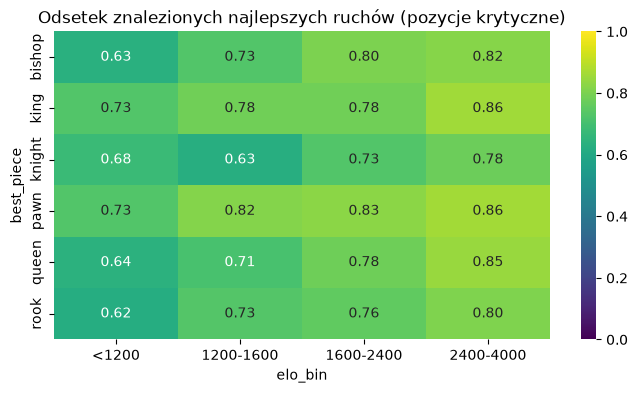

elo_bin,<1200,1200-1600,1600-2400,2400-4000
best_piece,,,,
bishop,304,276,380,339
king,176,197,279,396
knight,279,281,354,325
pawn,415,396,504,582
queen,411,414,487,402
rook,273,274,425,528


In [12]:
MIN_N = 20

g = crit.groupby(['best_piece', 'elo_bin'], observed=True)['found_best'].agg(n='count', rate='mean').reset_index()
rate = g.pivot(index='best_piece', columns='elo_bin', values='rate')
n = g.pivot(index='best_piece', columns='elo_bin', values='n')
rate_masked = rate.where(n >= MIN_N)

plt.figure(figsize=(8, 4))
sns.heatmap(rate_masked, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1)
plt.title('Odsetek znalezionych najlepszych ruchów (pozycje krytyczne)')
plt.show()
n

## 5. Jakie figury ruszają gracze, gdy popełniają błąd
Wiersze = figura najlepszego ruchu, kolumny = figura faktycznie ruszona (tylko pozycje krytyczne, w których gracz się pomylił).

In [13]:
errors = crit[~crit['found_best']]
pd.crosstab(errors['best_piece'], errors['played_piece'], normalize='index').round(2)

played_piece,bishop,king,knight,pawn,queen,rook
best_piece,,,,,,
bishop,0.25,0.11,0.18,0.20,0.14,0.11
king,0.07,0.53,0.09,0.09,0.06,0.15
knight,0.14,0.10,0.29,0.20,0.14,0.13
pawn,0.16,0.15,0.16,0.25,0.12,0.16
queen,0.14,0.07,0.13,0.19,0.36,0.11
rook,0.11,0.14,0.12,0.17,0.14,0.32


## 6. Kubełki: figura × kolumna × połowa planszy (rzeczywisty rozkład)
Dane z `critical_positions.csv` - **wszystkie** przeanalizowane pozycje, bez wyrównywania figur, więc liczby w kubełkach są takie, jakie wynikły z gier. (Rozkład Elo zależy tylko od kwot ustawionych w sekcji 2.)

Kubełek zależy od pola, z którego startuje figura wykonująca **najlepszy** ruch:
- **figura**: pion / skoczek / goniec / wieża / hetman / król,
- **kolumna** a-h (od lewej do prawej z perspektywy białych),
- **połowa**: „nasza” (rzędy 1-4 dla białych, 5-8 dla czarnych) albo „przeciwnika”.

Dla każdego kubełka: ile było pozycji (`n_positions`), ile krytycznych (`n_critical`, `critical_share`) i jak często gracz znalazł najlepszy ruch (`found_rate` z 95% przedziałem Wilsona). Szare komórki mają mniej niż `MIN_N` pozycji krytycznych - wynik tam jest przypadkowy.

In [14]:
import importlib, buckets as bk
importlib.reload(bk)          # po zmianie buckets.py nie trzeba restartować kernela

MIN_N = 10                    # minimalna liczba pozycji krytycznych, żeby pokazać odsetek

dfn = pd.read_csv('../data/critical_positionsv2.csv')
dfn = bk.add_bucket_columns(dfn)
print(f"{len(dfn)} pozycji z {dfn['game_id'].nunique()} partii, w tym krytycznych: {int(dfn['is_critical'].sum())}")
bk.summarize(dfn, ['best_piece'])

132460 pozycji z 2135 partii, w tym krytycznych: 8697


,best_piece,n_positions,n_critical,n_found,critical_share,found_rate,ci_low,ci_high
0,pawn,33197,1897,1542,0.057144,0.812862,0.794685,0.829775
1,knight,21811,1239,875,0.056806,0.706215,0.680245,0.730909
2,bishop,19737,1299,977,0.065815,0.752117,0.727915,0.774832
3,rook,20764,1500,1117,0.072240,0.744667,0.721994,0.766089
4,queen,18576,1714,1275,0.092270,0.743874,0.722680,0.763977
5,king,18375,1048,840,0.057034,0.801527,0.776296,0.824555


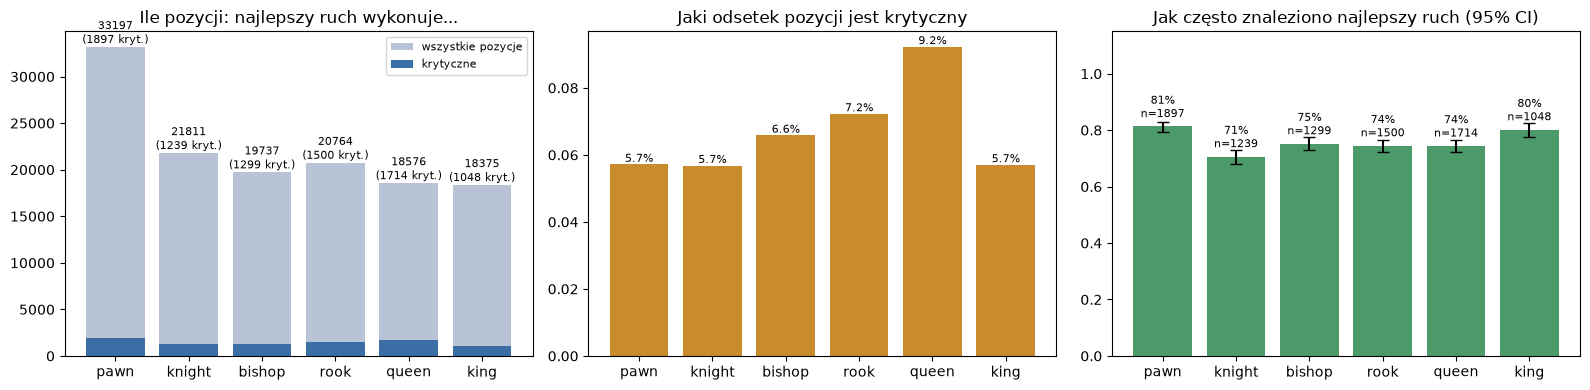

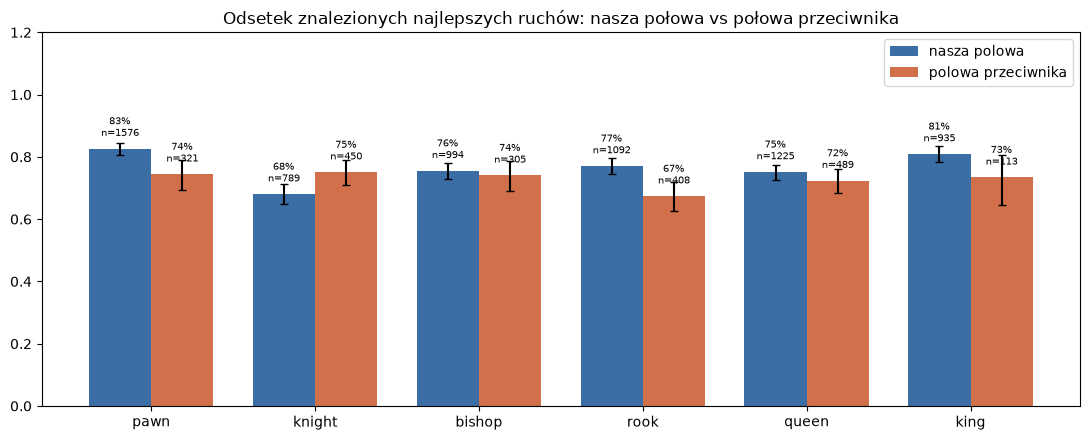

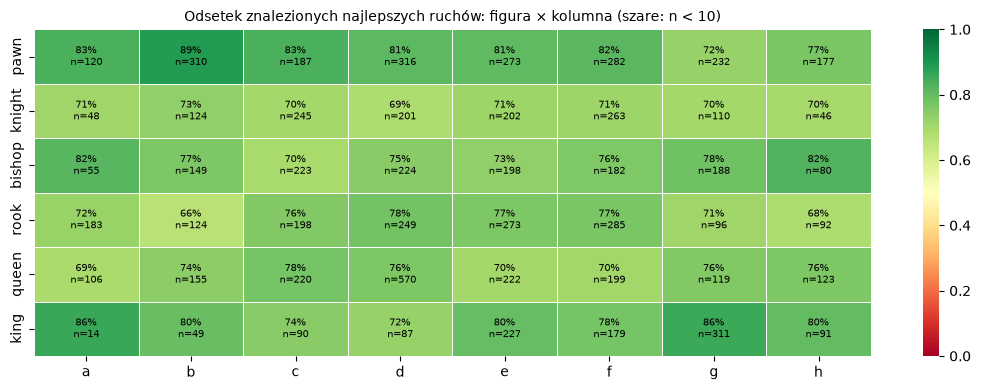

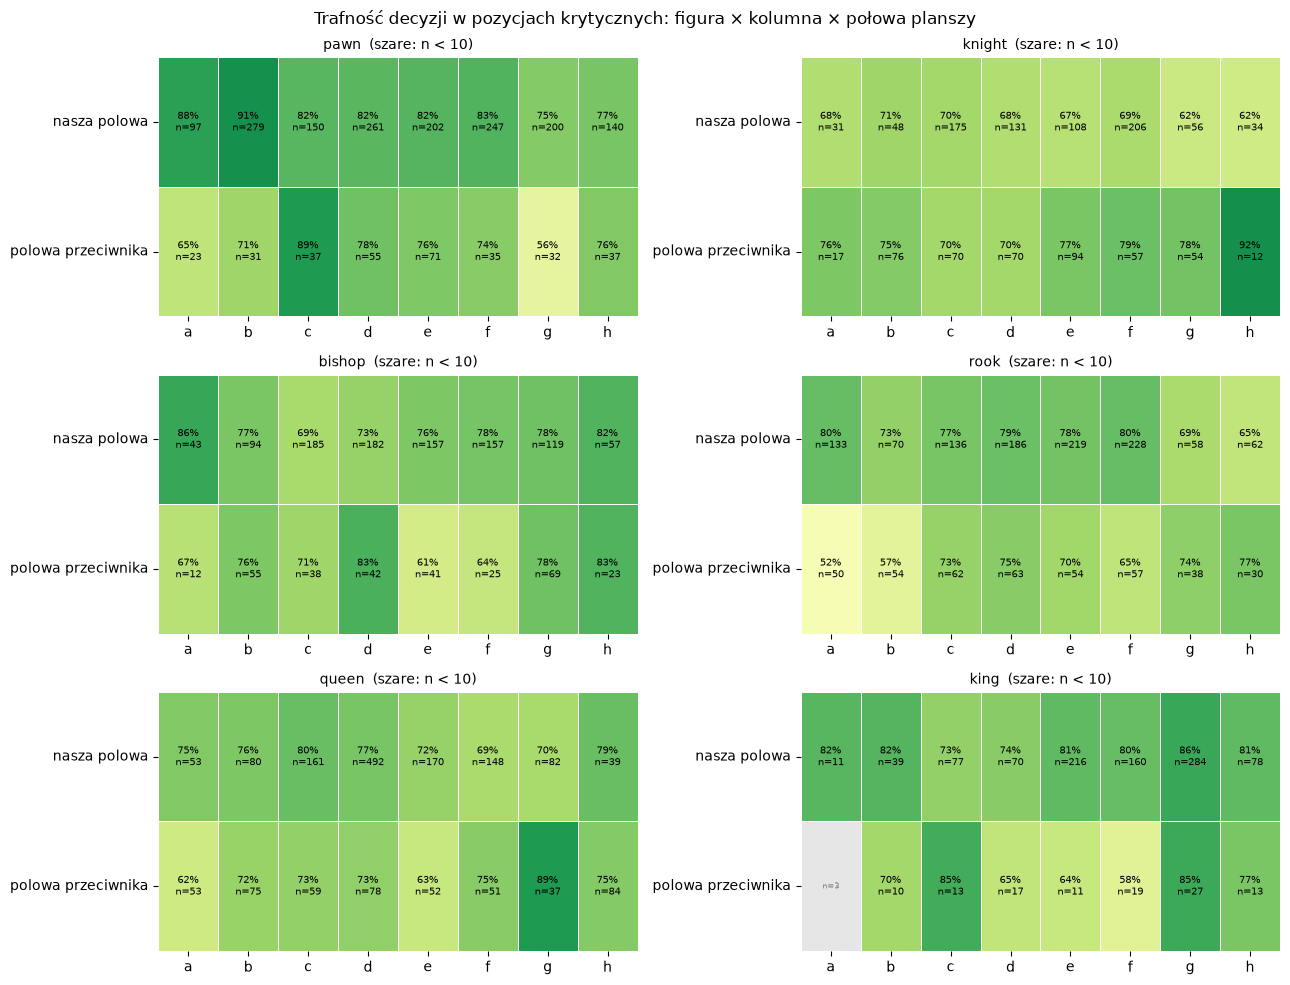

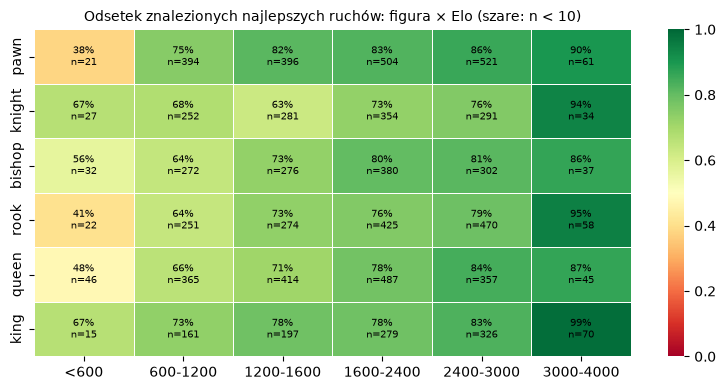

In [15]:
# 1) figura: ile pozycji / ile krytycznych / jak często dobra decyzja
bk.plot_piece_overview(dfn); plt.show()

# 2) figura x połowa planszy
bk.plot_half(dfn); plt.show()

# 3) figura x kolumna (a-h)
bk.plot_piece_file(dfn, MIN_N); plt.show()

# 4) wszystko naraz: figura x kolumna x połowa (96 kubełków)
bk.plot_full_buckets(dfn, MIN_N); plt.show()

# 5) figura x przedział Elo (przedziały możesz zmieniać)


bk.plot_piece_elo(dfn, bins = [0,600, 1200, 1600,2400 ,3000,4000],
                 labels = ['<600','600-1200' ,'1200-1600', '1600-2400', '2400-3000','3000-4000'], min_n=MIN_N); plt.show()

### Obrona przed szachem
Pozycja liczy się jako **obrona przed szachem**, gdy strona na ruchu ma szacha (kolumna `in_check`, liczona z FEN-u, więc nie trzeba nic analizować od nowa). Każdy legalny ruch jest wtedy obroną, a pozycje z jednym legalnym ruchem są i tak pomijane.

,check_status,n_positions,n_critical,n_found,critical_share,found_rate,ci_low,ci_high
0,obrona przed szachem,9119,1323,1111,0.145082,0.839758,0.819012,0.858537
1,bez szacha,123341,7374,5515,0.059785,0.747898,0.737860,0.757678


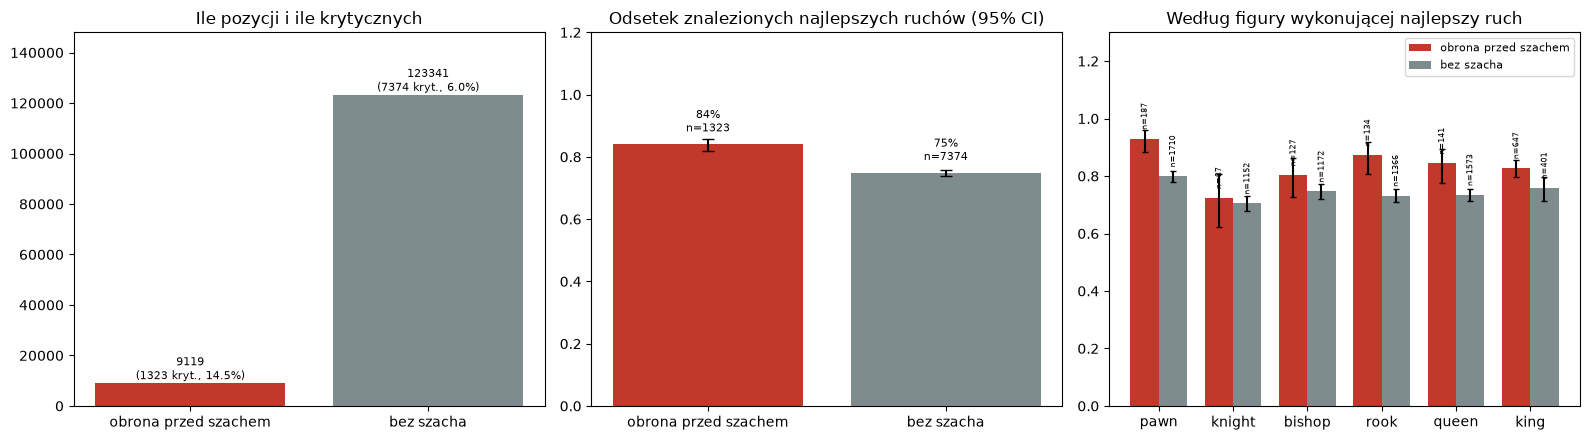

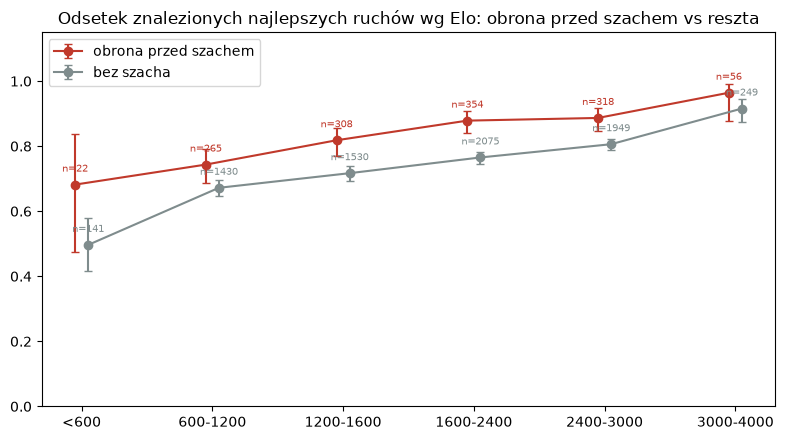

In [16]:
display(bk.summarize(dfn, ['check_status']))     # ile pozycji, ile krytycznych, jak często dobra decyzja

bk.plot_check(dfn); plt.show()                    # ogólnie i wg figury wykonującej najlepszy ruch
bk.plot_check_elo(dfn,bins = [0,600, 1200, 1600,2400 ,3000,4000],
                 labels = ['<600','600-1200' ,'1200-1600', '1600-2400', '2400-3000','3000-4000']); plt.show()

In [17]:
# pełna tabela kubełków (do pracy / Excela)
table = bk.bucket_table(dfn)
table.to_csv('../data/bucket_summary.csv', index=False)
table.sort_values('n_critical', ascending=False).head(20)

,best_piece,half,best_file,check_status,n_positions,n_critical,n_found,critical_share,found_rate,ci_low,ci_high
131,queen,nasza polowa,d,bez szacha,5564,438,329,0.078720,0.751142,0.708585,0.789331
7,pawn,nasza polowa,d,bez szacha,4390,258,210,0.058770,0.813953,0.761987,0.856707
11,pawn,nasza polowa,f,bez szacha,3330,226,186,0.067868,0.823009,0.767973,0.867247
103,rook,nasza polowa,f,bez szacha,3282,207,162,0.063071,0.782609,0.721545,0.833374
101,rook,nasza polowa,e,bez szacha,2211,205,159,0.092718,0.775610,0.713732,0.827348
9,pawn,nasza polowa,e,bez szacha,3877,198,163,0.051070,0.823232,0.764094,0.870066
168,king,nasza polowa,g,obrona przed szachem,1421,196,169,0.137931,0.862245,0.806993,0.903570
3,pawn,nasza polowa,b,bez szacha,3021,192,168,0.063555,0.875000,0.820744,0.914544
39,knight,nasza polowa,f,bez szacha,3998,192,131,0.048024,0.682292,0.613410,0.744022
99,rook,nasza polowa,d,bez szacha,2325,173,136,0.074409,0.786127,0.719158,0.840665


## Uwagi i ograniczenia
- Wynik zależy od głębokości (`depth`) i progu (`gap_threshold`) - warto opisać wybrane wartości w pracy i sprawdzić wrażliwość (np. 0.15 / 0.20 / 0.30).
- Ruchy wymuszone (1 legalny ruch) są pomijane; szachy z jedną sensowną odpowiedzią *nie* są pomijane, więc część pozycji krytycznych to oczywiste obrony przed szachem - można dodać filtr `board.is_check()`.
- Czas gry (bullet vs classical) mocno wpływa na błędy - rozważ filtrowanie po `TimeControl`.
- Próbka 100 partii to tylko test działania; do wniosków potrzeba kilku tysięcy partii.